# Mind the Stability Gap, Part 5
### A silver-mimic screen: what else could do silver's job?

**Author:** James Fox · Intro to AI & Machine Learning, Fall 2026

Part 4 found that bismuth passes every chemistry and safety check for replacing lead, but its solar cells are weak. In the best-known bismuth perovskite, Cs₂AgBiBr₆, bismuth can't work alone: Bi³⁺ carries a +3 charge, so it pairs with a +1 ion, silver, to average out to lead's +2.

Silver does three jobs in that crystal:
1. **Charge:** it holds a steady +1.
2. **Size:** it fits in the six-neighbor (octahedral) site between halides.
3. **Orbitals:** its filled 4d shell sits at almost the same energy as the halide's outer p orbitals. Orbitals at similar energies mix, so silver's electrons join the top of the valence band and give charges a path through the silver.

Sodium can do jobs 1 and 2 but not 3. This notebook asks: **which +1 ions can do all three, and what would a "pseudo-silver" have to look like?** It scores ten candidates using:
- **Shannon ionic radii** (via pymatgen) and Pauling's radius-ratio rule for size
- **Atomic orbital energies** from NIST's Atomic Reference Data (via pymatgen) for orbital matching
- **The Perovskite Database** for each ion's track record in lead-free devices

It ends with two ideas that came up while building this: giving tin a partner to make a +1 unit, and whether the perovskite geometry itself is the obstacle.

## 1. Setup

In [1]:
# Standard data-science stack; everything here comes pre-installed in Google Colab.
import os, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

# Chart style: quiet axes and gridlines so the data does the talking
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ab"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
SOURCE = "Source: The Perovskite Database (Jacobsson et al., Nature Energy 2022), CC BY 4.0"
thousands = lambda v, _: f"{v/1000:g}K" if v >= 1000 else f"{v:.0f}"

pct = lambda share: f"{share:.0%}" if share >= 0.005 else "<1%"

def save(fig, name):
    # Saves each chart as a high-resolution PNG in figures/ (ready for LinkedIn)
    fig.savefig(f"figures/{name}.png")
    plt.show()

def hbars(ax, labels, values, fmt, color=BLUE, pad=0.01, span=None):
    # Horizontal bars, top-to-bottom in the order given, with the value printed at each bar's tip
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.55, color=color)
    span = span or (max(values) if max(values) > 0 else 1)
    for yi, v in zip(y, values):
        ax.text(v + span * pad, yi, fmt(v), va="center", fontsize=10, color=INK_2)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, span * 1.3)
    ax.grid(axis="y", visible=False)

In [2]:
# pymatgen packages Shannon radii and NIST atomic orbital energies (takes about a minute to install in Colab)
%pip install -q pymatgen

## 2. Get the data (for the track-record columns)

In [3]:
DATA_URL = ("https://zenodo.org/records/5837035/files/"
            "Jesperkemist/perovskitedatabase_data-v1.0.1.zip?download=1")
ZIP_PATH = "perovskitedatabase_data-v1.0.1.zip"
CSV_NAME = "Perovskite_database_content_all_data.csv"

if not os.path.exists(ZIP_PATH):
    print("Downloading the Perovskite Database snapshot from Zenodo (about 3 MB)...")
    try:
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    except Exception as err:
        raise RuntimeError(
            f"Download failed ({err}). Open this link in your browser:\n{DATA_URL}\n"
            "then drag the zip into Colab's Files panel (folder icon, left side) and re-run this cell.")

with zipfile.ZipFile(ZIP_PATH) as zf:
    member = next(name for name in zf.namelist() if name.endswith(CSV_NAME))
    raw = pd.read_csv(zf.open(member), low_memory=False)

print(f"Loaded {len(raw):,} devices x {raw.shape[1]} columns")
raw[["Ref_DOI_number", "Ref_publication_date", "Cell_architecture",
     "Perovskite_composition_short_form", "JV_default_PCE", "Stability_measured"]].head()

Loaded 42,443 devices x 410 columns


,Ref_DOI_number,Ref_publication_date,Cell_architecture,Perovskite_composition_short_form,JV_default_PCE,Stability_measured
0,10.1021/jp5126624,2015-01-06,nip,CsSnI,0.00,False
1,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.00,False
2,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.13,False
3,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.12,False
4,10.1021/jp5126624,2015-01-06,nip,CsSnBr,0.10,False


In [4]:
MISSING = {"", "nan", "none", "unknown", "n/a", "na", "-"}

def get(name):
    # Returns a column, or an all-empty column if this snapshot doesn't have it
    return raw[name] if name in raw.columns else pd.Series(np.nan, index=raw.index)

def reported(series):
    # True where a cell holds real information rather than one of the 'missing' markers
    def check(v):
        if pd.isna(v):
            return False
        return any(tok.strip().lower() not in MISSING for tok in re.split(r"[;|>]+", str(v)))
    return series.map(check).astype(bool)

def to_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

def to_num(series):
    # Numbers stay numbers; text like '1.6 | nan' falls back to its first number
    direct = pd.to_numeric(series, errors="coerce")
    first = pd.to_numeric(series.astype(str).str.extract(r"(-?\d+(?:\.\d+)?)")[0], errors="coerce")
    return direct.fillna(first)

def range_max(series):
    # Largest number in a 'min; max' range ('25; 85' -> 85)
    def f(v):
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(v))
        return max(map(float, nums)) if nums else np.nan
    return series.map(f)

def text(series):
    return series.where(reported(series), "").astype(str).str.strip().str.lower()

def atmosphere_group(v):
    tokens = {t.strip() for t in re.split(r"[;|]", v) if t.strip()}
    if not tokens:
        return "Not reported"
    if tokens <= {"n2", "ar", "argon", "vacuum", "he", "inert"}:
        return "Inert (N2/Ar/vacuum)"
    if "dry air" in tokens:
        return "Dry air"
    if tokens & {"air", "ambient"}:
        return "Air / ambient"
    return "Other"

def bias_group(v):
    if not v:
        return "Not reported"
    for key, label in [("mpp", "MPP tracking"), ("open", "Open circuit"),
                       ("short", "Short circuit"), ("constant", "Constant bias")]:
        if key in v:
            return label
    return "Other"

TEST_TYPES = {  # ISOS category -> plain-English test type (conditions from Khenkin et al. 2020, Table 1)
    "d1": "Dark, room temperature (shelf life)",
    "d2": "Dark, heated to 65-85 °C",
    "d3": "Dark, 65-85 °C and 85% humidity (damp heat)",
    "l1": "Under light, room temperature",
    "l2": "Under light, heated to 65-85 °C",
    "l3": "Under light, heated, ~50% humidity",
    "o":  "Outdoors",
}
def test_type(v):
    v = v.replace("‐", "-").replace("‑", "-").replace(" ", "")   # some entries use unicode hyphens
    if not v:
        return "Not classified"
    m = re.match(r"isos-(lc|[dlotv])-?(\d)", v)
    if not m:
        return "Cycling, bias, IEC or other"
    kind = m.group(1) if m.group(1) == "o" else m.group(1) + m.group(2)
    return TEST_TYPES.get(kind, "Cycling, bias, IEC or other")

## 3. The candidates

Every common ion that can hold a +1 charge, grouped by what sits at the top of its electron shell once it has lost one electron:
- **Alkali metals** (Li⁺, Na⁺, K⁺, Rb⁺): a filled p shell (or 1s for lithium) buried deep in energy
- **Coinage metals** (Cu⁺, Ag⁺, Au⁺): a filled d shell
- **Lone-pair ions** (In⁺, Tl⁺): a filled s² pair, the same feature lead has (Part 4)
- **A molecule,** ammonium (NH₄⁺), to test the "molecular silver" idea

**Orbital energies** are the LDA values for neutral atoms from NIST's Atomic Reference Data for Electronic Structure Calculations, as packaged in pymatgen. They aren't the energies inside a crystal, where neighboring ions shift every level. What they do capture is the ordering: whether an ion's top electrons sit near the halide's or far from it. That ordering is what decides whether orbitals can mix.

In [5]:
from pymatgen.core import Element, Species
HA_TO_EV = 27.211386

# The highest filled orbital of each +1 ion, once its outermost s electron is gone
FILLED = {"Li": "1s", "Na": "2p", "K": "3p", "Rb": "4p",
          "Cu": "3d", "Ag": "4d", "Au": "5d", "In": "5s", "Tl": "6s"}
HALIDE_P = {"I": "5p", "Br": "4p", "Cl": "3p"}

def orbital_eV(sym, orb):
    # LDA orbital energy of the neutral atom (NIST SRD 141), stored by pymatgen in hartree
    return Element(sym).atomic_orbitals[orb] * HA_TO_EV

def shannon_VI(sym):
    try:
        return Species(sym, 1).get_shannon_radius("VI")
    except Exception:
        return np.nan   # In⁺ is not in Shannon's table

X_P = {x: orbital_eV(x, orb) for x, orb in HALIDE_P.items()}

# Does the +1 state survive in a halide crystal in air?
#   Cu⁺ oxidizes and prefers four neighbors over six (Xiao et al., Angew. Chem. 2017)
#   Au⁺ tends to split into Au⁰ and Au³⁺; In⁺ oxidizes to In³⁺ (Xiao et al., JACS 2017)
STABLE = {"Li": True, "Na": True, "K": True, "Rb": True, "Cu": False, "Ag": True,
          "Au": False, "In": False, "Tl": True, "NH4": True}
HAZARD = {"Li": "lower", "Na": "lower", "K": "lower", "Rb": "lower", "Cu": "lower", "Ag": "lower",
          "Au": "lower", "In": "moderate", "Tl": "high", "NH4": "lower"}
FAMILY = {"Li": "alkali", "Na": "alkali", "K": "alkali", "Rb": "alkali", "Cu": "coinage", "Ag": "coinage",
          "Au": "coinage", "In": "lone pair", "Tl": "lone pair", "NH4": "molecule"}

rows = []
for sym, orb in FILLED.items():
    rows.append({"ion": f"{sym}⁺", "family": FAMILY[sym], "radius_A": shannon_VI(sym),
                 "top_filled_orbital": orb, "top_filled_eV": orbital_eV(sym, orb)})
# Ammonium: effective radius 1.46 Å (Kieslich, Sun & Cheetham 2015). All eight valence electrons are
# locked in N–H bonds, so it has no orbital near the halide's (no single atomic value to list).
rows.append({"ion": "NH₄⁺", "family": "molecule", "radius_A": 1.46,
             "top_filled_orbital": "N–H bonds", "top_filled_eV": np.nan})
cand = pd.DataFrame(rows, index=list(FILLED) + ["NH4"])
cand["holds_plus1"] = pd.Series(STABLE)
cand["hazard"] = pd.Series(HAZARD)
for x in X_P:
    cand[f"offset vs {x} (eV)"] = cand["top_filled_eV"] - X_P[x]

print("Halide p-orbital energies (eV):", {x: round(v, 2) for x, v in X_P.items()})
cand.style.format({"radius_A": "{:.2f}", "top_filled_eV": "{:.2f}",
                   **{f"offset vs {x} (eV)": "{:+.2f}" for x in X_P}}, na_rep="—")

Halide p-orbital energies (eV): {'I': -7.29, 'Br': -8.04, 'Cl': -8.72}


,ion,family,radius_A,top_filled_orbital,top_filled_eV,holds_plus1,hazard,offset vs I (eV),offset vs Br (eV),offset vs Cl (eV)
Li,Li⁺,alkali,0.76,1s,-51.12,True,lower,-43.83,-43.08,-42.40
Na,Na⁺,alkali,1.02,2p,-28.86,True,lower,-21.57,-20.82,-20.14
K,K⁺,alkali,1.38,3p,-18.88,True,lower,-11.59,-10.84,-10.16
Rb,Rb⁺,alkali,1.52,4p,-16.11,True,lower,-8.82,-8.08,-7.40
Cu,Cu⁺,coinage,0.77,3d,-5.50,False,lower,+1.79,+2.53,+3.21
Ag,Ag⁺,coinage,1.15,4d,-8.13,True,lower,-0.84,-0.09,+0.59
Au,Au⁺,coinage,1.37,5d,-8.29,False,lower,-1.00,-0.26,+0.43
In,In⁺,lone pair,—,5s,-7.90,False,moderate,-0.61,+0.13,+0.81
Tl,Tl⁺,lone pair,1.50,6s,-7.76,True,high,-0.47,+0.28,+0.96
NH4,NH₄⁺,molecule,1.46,N–H bonds,—,True,lower,—,—,—


**Silver's 4d sits 0.09 eV from bromine's 4p.** That near-perfect match is silver's real advantage. Gold's 5d is almost as close. Copper's 3d sits about 2.5 eV higher, which Xiao *et al.* (2017) identified as the reason copper won't take six neighbors. The alkali metals' top electrons are 8 to 43 eV deeper, far out of reach. Indium's and thallium's lone pairs sit close to the halide too, which is why In⁺ and Tl⁺ would make good partners if they were stable and safe.

## 4. Size: does it fit the six-neighbor site?

Two checks, for each halide:
- **Radius ratio r / r_X between 0.414 and 0.732.** This is Pauling's classic window for an ion that prefers exactly six neighbors. Below it, the ion rattles in the cage; above it, the ion would rather have eight.
- **Tolerance factor 0.8 ≤ t ≤ 1.0** for the double perovskite Cs₂B⁺BiX₆, using the average radius of the +1 ion and Bi³⁺, the same check as Part 4.

The orbital check then asks whether the ion's top filled orbital sits **within 1 eV** of the p orbital of a halide it fits with.

In [6]:
R_CS, R_BI = 1.88, 1.03
R_X = {"I": 2.20, "Br": 1.96, "Cl": 1.81}
RATIO_MIN, RATIO_MAX = 0.414, 0.732
ORBITAL_WINDOW = 1.0   # eV

geo_rows = []
for sym, r in cand.iterrows():
    entry = {}
    for x, r_x in R_X.items():
        if np.isnan(r["radius_A"]):
            entry[f"fits {x}"] = None
        else:
            ratio = r["radius_A"] / r_x
            t = (R_CS + r_x) / (np.sqrt(2) * ((r["radius_A"] + R_BI) / 2 + r_x))
            entry[f"ratio {x}"], entry[f"t {x}"] = ratio, t
            entry[f"fits {x}"] = (RATIO_MIN <= ratio <= RATIO_MAX) and (0.8 <= t <= 1.0)
        entry[f"orbital {x}"] = (abs(r[f"offset vs {x} (eV)"]) <= ORBITAL_WINDOW) if not np.isnan(r["top_filled_eV"]) else False
    geo_rows.append(pd.Series(entry, name=sym))
geo = pd.DataFrame(geo_rows)

def fits_with(sym):
    known = [x for x in R_X if geo.loc[sym, f"fits {x}"] is not None]
    if not known:
        return None
    return [x for x in R_X if geo.loc[sym, f"fits {x}"]]

def orbital_match(sym):
    # Orbital match with a halide the ion fits; if its size is unknown, with any halide
    halides = fits_with(sym)
    halides = list(R_X) if halides is None else halides
    return any(geo.loc[sym, f"orbital {x}"] for x in halides)

cand["fits with"] = [("unknown" if fits_with(s) is None else (", ".join(fits_with(s)) or "none")) for s in cand.index]
cand["orbital match"] = [orbital_match(s) for s in cand.index]
show = geo[[c for c in geo.columns if c.startswith(("ratio", "t "))]].copy()
show["fits with"] = cand["fits with"]
show.style.format("{:.2f}", subset=[c for c in show.columns if c != "fits with"], na_rep="—")

,ratio I,t I,ratio Br,t Br,ratio Cl,t Cl,fits with
Li,0.35,0.93,0.39,0.95,0.42,0.96,Cl
Na,0.46,0.89,0.52,0.91,0.56,0.92,"I, Br, Cl"
K,0.63,0.85,0.70,0.86,0.76,0.87,"I, Br"
Rb,0.69,0.83,0.78,0.84,0.84,0.85,I
Cu,0.35,0.93,0.39,0.95,0.43,0.96,Cl
Ag,0.52,0.88,0.59,0.89,0.64,0.90,"I, Br, Cl"
Au,0.62,0.85,0.70,0.86,0.76,0.87,"I, Br"
In,—,—,—,—,—,—,unknown
Tl,0.68,0.83,0.77,0.84,0.83,0.85,I
NH4,0.66,0.84,0.74,0.85,0.81,0.85,I


**Size is the easy part.** Most +1 ions fit with at least one halide, which matches experiment: Cs₂LiYCl₆ is a commercial radiation-detector crystal, Cs₂NaBiI₆ has been made, and sodium can replace 40% of the silver in Cs₂AgInCl₆ (Luo *et al.*, *Nature* 2018). Copper squeaks in only with chloride, and only on paper. In⁺ isn't in Shannon's table, so its size is marked unknown.

## 5. The scorecard

Four pass/fail checks:
1. **Holds +1 in air**
2. **Size fits** with at least one halide (section 4)
3. **Orbitals match** the halide it fits with, within 1 eV
4. **Lower toxicity** (thallium is highly toxic; indium compounds are flagged moderate, as in Part 4)

The **track record** columns count lead-free devices in the Perovskite Database that list each ion, and where the curators placed it.

,Holds +1 in air,Size fits,Orbitals match,Lower toxicity,Score (of 4),Lead-free devices,Best efficiency (%)
ion,,,,,,,
Ag⁺,✓,✓,✓,✓,4,125,4.30
K⁺,✓,✓,✗,✓,3,16,0.20
NH₄⁺,✓,✓,✗,✓,3,14,0.51
Rb⁺,✓,✓,✗,✓,3,8,1.41
Na⁺,✓,✓,✗,✓,3,1,0.42
Au⁺,✗,✓,✓,✓,3,1,0.01
Li⁺,✓,✓,✗,✓,3,0,—
Tl⁺,✓,✓,✓,✗,3,0,—
Cu⁺,✗,✓,✗,✓,2,13,2.00


ion,Li⁺,Na⁺,K⁺,Rb⁺,Cu⁺,Ag⁺,Au⁺,In⁺,Tl⁺,NH₄⁺
listed at A-site,0.0,1.0,16.0,8.0,2.0,116.0,0.0,0.0,0.0,14.0
listed at B-site,0.0,0.0,0.0,0.0,11.0,9.0,1.0,0.0,0.0,0.0


Ions passing the orbital check at 1 eV: Ag, Au, In, Tl
Same answer for any window from 0.5 to 3.2 eV


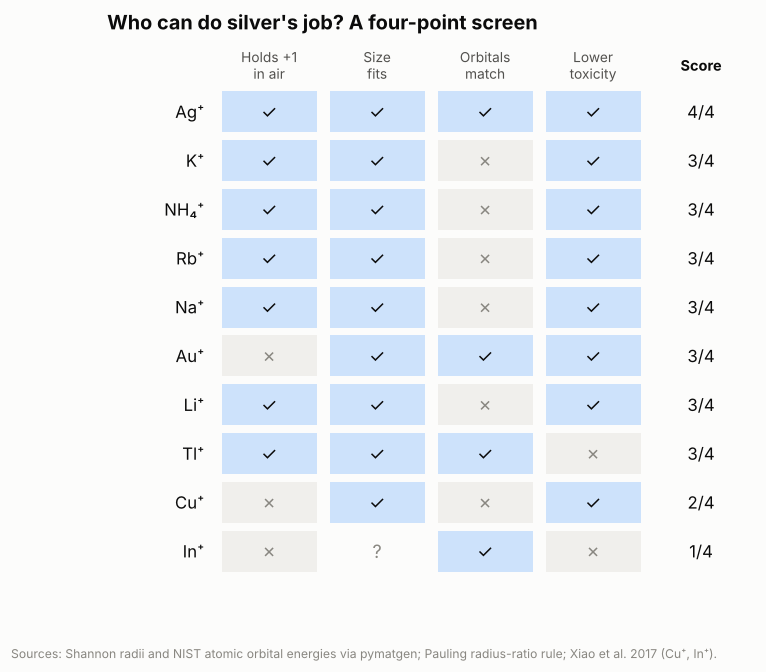

In [7]:
tok = lambda s: {t.strip().strip("()") for t in re.split(r"[;|]", str(s)) if t.strip()}
a_ions = get("Perovskite_composition_a_ions").fillna("").map(tok)
b_ions = get("Perovskite_composition_b_ions").fillna("").map(tok)
pce = to_num(get("JV_default_PCE"))
lead_free = b_ions.map(lambda t: not ({"Pb", "Sn"} & t))
for sym in cand.index:
    in_a, in_b = a_ions.map(lambda t: sym in t) & lead_free, b_ions.map(lambda t: sym in t) & lead_free
    cand.loc[sym, "lead-free devices"] = int((in_a | in_b).sum())
    cand.loc[sym, "listed at A-site"] = int(in_a.sum())
    cand.loc[sym, "listed at B-site"] = int(in_b.sum())
    cand.loc[sym, "best efficiency (%)"] = pce[in_a | in_b].max()

CHECKS = {
    "Holds +1 in air": cand["holds_plus1"],
    "Size fits": cand["fits with"].map(lambda v: None if v == "unknown" else v != "none"),
    "Orbitals match": cand["orbital match"],
    "Lower toxicity": cand["hazard"].eq("lower"),
}
score = pd.DataFrame(CHECKS)
score["Score (of 4)"] = score.apply(lambda r: sum(v is True or v == True for v in r if v is not None), axis=1)
score[["Lead-free devices", "Best efficiency (%)"]] = cand[["lead-free devices", "best efficiency (%)"]]
score.index = cand["ion"]
score = score.sort_values(["Score (of 4)", "Lead-free devices"], ascending=False)

def mark(v):
    if v is None or (isinstance(v, float) and np.isnan(v)): return "?"
    return "✓" if bool(v) else "✗"
shown = score.copy()
for c in CHECKS:
    shown[c] = shown[c].map(mark)
display(shown.style.format({"Lead-free devices": "{:.0f}", "Best efficiency (%)": "{:.2f}"}, na_rep="—"))
display(cand[["ion", "listed at A-site", "listed at B-site"]].set_index("ion").T)

# Does the result depend on the 1 eV window? Check every window from 0.5 to 2.0 eV
def orbital_passers(window):
    passed = []
    for sym in cand.index:
        halides = fits_with(sym)
        halides = list(R_X) if halides is None else halides
        if any(abs(cand.loc[sym, f"offset vs {x} (eV)"]) <= window for x in halides
               if not np.isnan(cand.loc[sym, "top_filled_eV"])):
            passed.append(sym)
    return tuple(passed)
# Walk outward from 1 eV in 0.05 eV steps until the set of passing ions changes
base = orbital_passers(ORBITAL_WINDOW)
lo = hi = ORBITAL_WINDOW
while lo - 0.05 > 0 and orbital_passers(round(lo - 0.05, 2)) == base:
    lo = round(lo - 0.05, 2)
while hi + 0.05 < 10 and orbital_passers(round(hi + 0.05, 2)) == base:
    hi = round(hi + 0.05, 2)
stable_range = [lo, hi]
print(f"Ions passing the orbital check at 1 eV: {', '.join(orbital_passers(ORBITAL_WINDOW))}")
print(f"Same answer for any window from {lo} to {hi} eV")

# A picture of the scorecard for sharing
HEADERS = ["Holds +1\nin air", "Size\nfits", "Orbitals\nmatch", "Lower\ntoxicity"]
fig, ax = plt.subplots(figsize=(7.6, 0.5 * len(score) + 1.4))
ax.set_xlim(0, len(CHECKS) + 2); ax.set_ylim(len(score) - 0.4, -1.5); ax.axis("off")
for j, header in enumerate(HEADERS):
    ax.text(j + 1.5, -0.95, header, ha="center", va="center", fontsize=9, color=INK_2)
ax.text(len(CHECKS) + 1.5, -0.95, "Score", ha="center", va="center", fontsize=9.5, color=INK, fontweight="bold")
for i, (ion, r) in enumerate(score.iterrows()):
    ax.text(0.9, i, ion, ha="right", va="center", fontsize=11, color=INK)
    for j, crit in enumerate(CHECKS):
        v = r[crit]
        known = v is not None and not (isinstance(v, float) and np.isnan(v))
        face = "#cde2fb" if known and bool(v) else ("#f0efec" if known else SURFACE)
        ax.add_patch(plt.Rectangle((j + 1.06, i - 0.42), 0.88, 0.84, color=face, lw=0))
        ax.text(j + 1.5, i, mark(v), ha="center", va="center", fontsize=12,
                color=INK if (known and bool(v)) else MUTED)
    ax.text(len(CHECKS) + 1.5, i, f"{r['Score (of 4)']}/4", ha="center", va="center", fontsize=11, color=INK)
ax.set_title("Who can do silver's job? A four-point screen", loc="left", pad=6)
fig.text(0.01, 0.0, "Sources: Shannon radii and NIST atomic orbital energies via pymatgen; Pauling radius-ratio rule; "
         "Xiao et al. 2017 (Cu⁺, In⁺).", fontsize=8, color=MUTED)
save(fig, "15_silver_mimic_scorecard")

**The 1 eV cutoff isn't doing the work:** the same four ions pass the orbital check for any window from 0.5 to 3.2 eV.

**Silver is the only ion that passes all four, and that's a useful sanity check:** a screen built from first principles picks out the ion chemists actually use. Every other candidate fails on a different check, which is why no single substitute has emerged:
- **Sodium, potassium, rubidium, lithium and ammonium** hold +1 and fit, but their electrons sit nowhere near the halide's. They can hold the crystal together but can't carry charge.
- **Gold** matches on orbitals but won't stay +1, and it's far more expensive than silver.
- **Thallium** passes everything except toxicity.
- **Copper and indium** both fail on stability, and copper's orbitals are too high as well.

The track record agrees. Silver appears in far more lead-free devices than any other +1 ion. Potassium, rubidium and ammonium appear only at the A-site, in compounds like (NH₄)₃Sb₂I₉ and Rb₃Sb₂I₉ or in oxides, never in silver's role. The single sodium device is a Cs₂NaBiI₆ cell at 0.42%.

## 6. The map: where would a pseudo-silver have to land?

Each ion is placed by its size relative to the halide it fits best (x) and how far its top filled orbital sits from that halide's p orbital (y). The shaded box is the target: the right size for six neighbors and within 1 eV in energy.

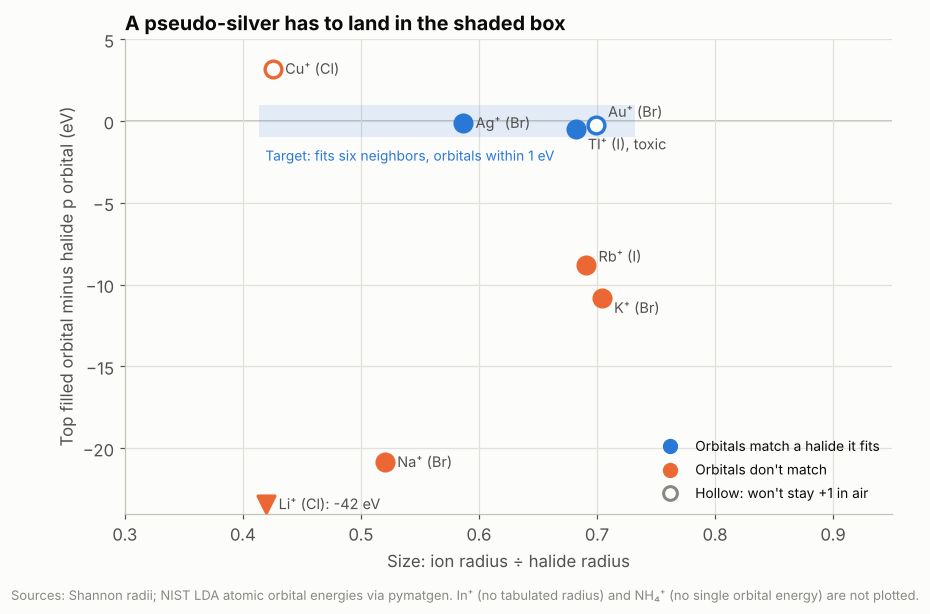

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.add_patch(plt.Rectangle((RATIO_MIN, -ORBITAL_WINDOW), RATIO_MAX - RATIO_MIN, 2 * ORBITAL_WINDOW,
                           color=BLUE, alpha=0.12, lw=0, zorder=1))
ax.text(RATIO_MIN + 0.005, -ORBITAL_WINDOW - 0.6, "Target: fits six neighbors, orbitals within 1 eV",
        fontsize=9, color=BLUE, va="top")
Y_FLOOR = -24
LABEL_OFFSETS = {"Au": (8, 9), "Tl": (8, -10), "K": (8, -6), "Rb": (8, 6)}
for sym, r in cand.iterrows():
    if np.isnan(r["radius_A"]) or np.isnan(r["top_filled_eV"]):
        continue
    halides = fits_with(sym) or ["Br"]
    x_best = "Br" if "Br" in halides else halides[0]
    x = r["radius_A"] / R_X[x_best]
    y = r[f"offset vs {x_best} (eV)"]
    clipped = y < Y_FLOOR
    y_plot = max(y, Y_FLOOR + 0.6)
    color = BLUE if r["orbital match"] else ORANGE
    ax.scatter(x, y_plot, s=120, zorder=3, facecolor=color if r["holds_plus1"] else SURFACE,
               edgecolor=color, linewidth=2.2, marker="v" if clipped else "o")
    label = f"{r['ion']} ({x_best})"
    if r["hazard"] == "high":
        label += ", toxic"
    if clipped:
        label += f": {y:.0f} eV"
    dx, dy = LABEL_OFFSETS.get(sym, (8, 0))
    ax.annotate(label, (x, y_plot), xytext=(dx, dy), textcoords="offset points", va="center", fontsize=9.5, color=INK_2)
ax.axhline(0, color=GRAY, lw=1, zorder=0)
ax.set_xlim(0.3, 0.95); ax.set_ylim(Y_FLOOR, 5)
ax.set_xlabel("Size: ion radius ÷ halide radius")
ax.set_ylabel("Top filled orbital minus halide p orbital (eV)")
ax.set_title("A pseudo-silver has to land in the shaded box")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", ms=9, mfc=BLUE, mec=BLUE, label="Orbitals match a halide it fits"),
           Line2D([], [], marker="o", ls="", ms=9, mfc=ORANGE, mec=ORANGE, label="Orbitals don't match"),
           Line2D([], [], marker="o", ls="", ms=9, mfc=SURFACE, mec=MUTED, mew=2, label="Hollow: won't stay +1 in air")]
ax.legend(handles=handles, frameon=False, loc="lower right", fontsize=9)
fig.text(0.01, -0.03, "Sources: Shannon radii; NIST LDA atomic orbital energies via pymatgen. In⁺ (no tabulated radius) and "
         "NH₄⁺ (no single orbital energy) are not plotted.", fontsize=8.5, color=MUTED)
save(fig, "16_silver_mimic_map")

**Reading the map.** Only three ions land in the box: silver, gold and thallium. Gold won't stay +1 and costs far more than silver; thallium is highly toxic. Everything cheap and abundant sits far below the box, with the alkali metals' top electrons 8 to 43 eV too deep. Copper sits above it, its d shell too high.

That empty space is the opportunity. A **pseudo-silver** would be a cheap ion, cluster or molecule that lands inside the box and stays +1 in air. Nothing on the periodic table does, so if one exists it has to be built.

## 7. An idea: give tin something to hold

Could tin itself become the +1 partner? Tin normally gives up two electrons (Sn²⁺). If it held onto one partner atom with a covalent bond, the unit [Sn–R]⁺ would carry a +1 charge.

**Charge and oxidation state aren't the same thing.** In [Sn–R]⁺, tin still has its 5s² lone pair and is formally Sn(II). The unit would look less like Ag⁺ and more like **In⁺**, which is also +1 with a 5s² pair. That makes it a pseudo-indium: the partner Part 4 called ideal, except that real In⁺ oxidizes.

**Who holds the electrons decides which way this goes.** For the partner to pull tin toward +1, it has to be more electronegative than tin:

In [9]:
partners = ["Na", "H", "C", "N", "I"]
en = pd.DataFrame({"partner": partners,
                   "electronegativity": [Element(p).X for p in partners]})
en["difference vs Sn"] = en["electronegativity"] - Element("Sn").X
en["pulls electrons from tin?"] = en["difference vs Sn"].map(lambda d: "yes" if d > 0 else "no, it gives them to tin")
print(f"Tin's electronegativity (Pauling): {Element('Sn').X}")
en.style.format({"electronegativity": "{:.2f}", "difference vs Sn": "{:+.2f}"}).hide(axis="index")

Tin's electronegativity (Pauling): 1.96


partner,electronegativity,difference vs Sn,pulls electrons from tin?
Na,0.93,-1.03,"no, it gives them to tin"
H,2.20,+0.24,yes
C,2.55,+0.59,yes
N,3.04,+1.08,yes
I,2.66,+0.70,yes


What the table means for each option:
- **Sodium goes the wrong way.** It's far less electronegative than tin, so it hands tin electrons instead of taking them. That's why sodium–tin compounds are Zintl phases with *negative* tin: NaSn is built from Sn₄⁴⁻ clusters.
- **Hydrogen pulls the right way, but weakly, and doesn't stay.** Tin–hydrogen bonds are weak: stannane (SnH₄) decomposes near room temperature, and tributyltin hydride is used in labs precisely because it gives up its hydrogen so easily.
- **A carbon group works in molecules.** Tin(II) cations with one bulky organic ring attached, such as [Cp\*Sn]⁺, are known compounds (reviewed by Jutzi & Burford, 1999). They survive only with bulky groups and weakly bound anions. In a halide crystal, they'd likely grab halides.

**The geometry problem.** In a perovskite, the six positions around a B-site metal are halide sites. Whatever tin holds onto has to occupy one of them. So a Sn–H unit in the lattice is really a hydride ion taking a halide's place, giving SnX₅H octahedra: a change at the X-site, not a new +1 ion. That leads straight to your next question.

## 8. Maybe the geometry is the problem

The perovskite framework sets strict rules: corner-sharing octahedra, one size window, one charge balance. Lead fits those rules almost perfectly; most other elements are forced into them. Other frameworks relax the rules:
- **Vacancy-ordered (Cs₂SnI₆):** every other metal site is empty, so tin can sit in the +4 state it prefers. The compound is stable in air and moisture (Lee *et al.*, *JACS* 2014). Tin stops fighting oxidation because there's nothing left to oxidize.
- **Rock-salt (AgBiS₂):** not a perovskite at all, yet it gives bismuth's best results: films above 10% and quantum dots at 9.2% (Grandhi *et al.*, 2025).
- **Layered and chain structures:** these make room for large organic cations, but they usually cut the paths charges travel along.

**The rule that matters isn't "be a perovskite."** It's that the orbitals at the band edges have to connect in all three directions, which Xiao *et al.* (2017) call **electronic dimensionality**. Lead perovskites have it naturally; Cs₂AgBiBr₆ only partly, because silver's orbitals don't match bismuth's symmetry. A new geometry is worth exploring if it keeps that 3D connection while giving tin or bismuth a site they actually like.

## 9. Where this points

1. **Silver is hard to replace because of an energy coincidence,** not because it's a noble metal: its filled 4d shell sits within 0.1 eV of bromine's 4p.
2. **The periodic table runs out.** Every ion with matching orbitals is expensive (Au), unstable (Au⁺, In⁺, Cu⁺) or toxic (Tl⁺). Every cheap one fails the orbital check.
3. **A pseudo-silver would have to be built:** a cheap, stable +1 unit whose top electrons sit within about 1 eV of the halide's p orbital and that fits six neighbors. That's a concrete target for computational screening of molecules and clusters.
4. **Tin as a +1 unit is chemically real in molecules ([Cp\*Sn]⁺), but a perovskite can't host it,** because its partner would take a halide's place. That points toward new frameworks rather than new partners.

**Limits of this screen:** orbital energies are for neutral atoms, not ions in a crystal; radii treat ions as hard spheres; "holds +1 in air" and toxicity are literature labels, not measurements; and passing a screen says nothing about efficiency.

In [10]:
s5 = {"passes_all_checks": ", ".join(score.index[score["Score (of 4)"] == len(CHECKS)]),
      "orbital_match_ions": ", ".join(cand.loc[list(orbital_passers(ORBITAL_WINDOW)), "ion"]),
      "ag_4d_minus_br_4p_eV": cand.loc["Ag", "offset vs Br (eV)"],
      "cu_3d_minus_br_4p_eV": cand.loc["Cu", "offset vs Br (eV)"],
      "na_2p_minus_br_4p_eV": cand.loc["Na", "offset vs Br (eV)"],
      "orbital_window_stable_range_eV": f"{lo}-{hi}"}
pd.Series(s5).to_csv("part5_summary.csv", header=["value"])
pd.Series(s5)

passes_all_checks                                Ag⁺
orbital_match_ions                Ag⁺, Au⁺, In⁺, Tl⁺
ag_4d_minus_br_4p_eV                       -0.091757
cu_3d_minus_br_4p_eV                        2.532346
na_2p_minus_br_4p_eV                      -20.824928
orbital_window_stable_range_eV               0.5-3.2
dtype: object

## Sources
- Shannon, R.D. Revised effective ionic radii. *Acta Cryst.* A32, 751–767 (1976), via pymatgen.
- Kotochigova, S. *et al.* Atomic Reference Data for Electronic Structure Calculations, NIST Standard Reference Database 141 (LDA orbital energies of neutral atoms), via pymatgen.
- Pauling, L. The principles determining the structure of complex ionic crystals. *J. Am. Chem. Soc.* 51, 1010 (1929).
- Kieslich, G., Sun, S. & Cheetham, A.K. An extended tolerance factor approach for organic–inorganic perovskites. *Chem. Sci.* 6, 3430 (2015), [doi:10.1039/c5sc00961h](https://doi.org/10.1039/c5sc00961h).
- Volonakis, G. *et al.* Lead-free halide double perovskites via heterovalent substitution of noble metals. *J. Phys. Chem. Lett.* 7, 1254 (2016), [arXiv:1603.01585](https://arxiv.org/abs/1603.01585).
- Xiao, Z. *et al.* Chemical origin of the stability difference between copper(I)- and silver(I)-based halide double perovskites. *Angew. Chem. Int. Ed.* 56 (2017), [OSTI 1533112](https://www.osti.gov/biblio/1533112).
- Xiao, Z. *et al.* Intrinsic instability of Cs₂In(I)M(III)X₆ double perovskites. *J. Am. Chem. Soc.* 139, 6054 (2017).
- Xiao, Z., Meng, W., Wang, J., Mitzi, D.B. & Yan, Y. Searching for promising new perovskite-based photovoltaic absorbers: the importance of electronic dimensionality. *Mater. Horiz.* 4, 206 (2017), [doi:10.1039/C6MH00519E](https://doi.org/10.1039/C6MH00519E).
- Luo, J. *et al.* Efficient and stable emission of warm-white light from lead-free halide double perovskites. *Nature* 563, 541 (2018), [doi:10.1038/s41586-018-0691-0](https://doi.org/10.1038/s41586-018-0691-0).
- Zhang, C. *et al.* Design of a novel and highly stable lead-free Cs₂NaBiI₆ double perovskite for photovoltaic application. *Sustainable Energy Fuels* (2018), [doi:10.1039/c8se00154e](https://doi.org/10.1039/c8se00154e).
- Lee, B. *et al.* Air-stable molecular semiconducting iodosalts for solar cell applications: Cs₂SnI₆ as a hole conductor. *J. Am. Chem. Soc.* 136, 15379 (2014), [doi:10.1021/ja508464w](https://doi.org/10.1021/ja508464w).
- Grandhi, G.K. *et al.* Silver–bismuth perovskite-inspired materials. *J. Mater. Chem. A* (2025), [doi:10.1039/D5TA06180F](https://doi.org/10.1039/D5TA06180F).
- Jutzi, P. & Burford, N. Structurally diverse π-cyclopentadienyl complexes of the main group elements. *Chem. Rev.* 99, 969 (1999).